In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Google Colab
PATH = Path("/content/data")

# Local (comment the Colab line above and uncomment this line)
# PATH = Path("diplomacy-deception-detection/data/raw")

for filename in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    print(filename, ":", (PATH / filename).exists())

train.jsonl : True
validation.jsonl : True
test.jsonl : True


#### Load all three JSONL files

In [3]:
def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Invalid JSON in {path}, line {line_number}") from e
    return records

In [4]:
splits = {}
for split in ["train", "validation", "test"]:
    splits[split] = read_jsonl(PATH / f"{split}.jsonl")
    print(f"{split}: {len(splits[split])} conversation records")

train: 189 conversation records
validation: 21 conversation records
test: 42 conversation records


#### Check required fields

In [5]:
# Find conversation records that are missing fields needed for message-level analysis
# required fields
required_fields = [
    "game_id", "players", "messages", "speakers", "receivers",
    "sender_labels", "receiver_labels", "absolute_message_index",
    "relative_message_index", "seasons", "years",
    "game_score", "game_score_delta"
]

missing_fields = []
for split, records in splits.items():
    for i, record in enumerate(records):
        missing = [field for field in required_fields if field not in record]
        if missing:
            missing_fields.append({
                "split": split, "conversation_index": i,
                "missing_fields": missing
            })

print("Records with missing fields:", len(missing_fields))

Records with missing fields: 0


### Check message-array alignment


In [7]:
message_fields = [
    "messages", "speakers", "receivers", "sender_labels",
    "receiver_labels", "absolute_message_index",
    "relative_message_index", "seasons", "years",
    "game_score", "game_score_delta"
]

In [8]:
alignment_issues = []
for split, records in splits.items():
    for i, record in enumerate(records):
        lengths = {
            field: len(record[field])
            for field in message_fields
            if isinstance(record.get(field), list)
        }
        if len(lengths) != len(message_fields) or len(set(lengths.values())) != 1:
            alignment_issues.append({
                "split": split, "conversation_index": i,
                "game_id": record.get("game_id"),
                "lengths": lengths
            })

print("Records with alignment issues:", len(alignment_issues))


Records with alignment issues: 0


#### Create a message-level DataFrame

One row represents one message. Records with missing or misaligned arrays are skipped for this analysis only; the raw files remain unchanged

In [9]:
rows = []
skipped_records = 0

for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        if any(not isinstance(record.get(field), list) for field in message_fields):
            skipped_records += 1
            continue

        n = len(record["messages"])
        if any(len(record[field]) != n for field in message_fields):
            skipped_records += 1
            continue

        for i in range(n):
            rows.append({
                "split": split,
                "game_id": record.get("game_id"),
                "conversation_index": conversation_index,
                "message_position": i,
                "message": record["messages"][i],
                "speaker": record["speakers"][i],
                "receiver": record["receivers"][i],
                "sender_label": record["sender_labels"][i],
                "receiver_label": record["receiver_labels"][i],
                "absolute_message_index": record["absolute_message_index"][i],
                "relative_message_index": record["relative_message_index"][i],
                "season": record["seasons"][i],
                "year": record["years"][i],
                "game_score": record["game_score"][i],
                "score_delta": record["game_score_delta"][i],
            })

df = pd.DataFrame(rows)
print("DataFrame shape:", df.shape)
print("Skipped records:", skipped_records)

DataFrame shape: (17289, 15)
Skipped records: 0


In [10]:
display(df.head(5))

,split,game_id,conversation_index,message_position,message,speaker,receiver,sender_label,receiver_label,absolute_message_index,relative_message_index,season,year,game_score,score_delta
0,train,1,0,0,Germany!\n\nJust the person I want to speak wi...,italy,germany,True,True,74,0,Spring,1901,3,0
1,train,1,0,1,"You've whet my appetite, Italy. What's the sug...",germany,italy,True,True,76,1,Spring,1901,3,0
2,train,1,0,2,👍,italy,germany,True,True,86,2,Spring,1901,3,0
3,train,1,0,3,It seems like there are a lot of ways that cou...,germany,italy,True,True,87,3,Spring,1901,3,0
4,train,1,0,4,"Yeah, I can’t say I’ve tried it and it works, ...",italy,germany,True,NOANNOTATION,89,4,Spring,1901,3,0


In [12]:
# Null values by column
display(df.isna().sum().sort_values(ascending=False).to_frame("null_count"))


,null_count
split,0
game_id,0
conversation_index,0
message_position,0
message,0
speaker,0
receiver,0
sender_label,0
receiver_label,0
absolute_message_index,0


In [13]:
empty_messages = df["message"].fillna("").astype(str).str.strip().eq("")
print("Empty or whitespace-only messages:", empty_messages.sum())

Empty or whitespace-only messages: 0


#### Inspect sender and receiver labels

In [14]:
print("Sender label values:")
display(df.groupby(["split", "sender_label"], dropna=False).size().to_frame("count"))


Sender label values:


count
split      sender_label       
test       False           240
           True           2501
train      False           591
           True          12541
validation False            56
           True           1360

In [15]:
print("Receiver label values:")
display(df.groupby(["split", "receiver_label"], dropna=False).size().to_frame("count"))


Receiver label values:


count
split      receiver_label       
test       False             165
           True             2310
           NOANNOTATION      266
train      False             566
           True            11459
           NOANNOTATION     1107
validation False              47
           True             1236
           NOANNOTATION      133

In [16]:
valid_sender = {True, False}
valid_receiver = {True, False, "NOANNOTATION"}

invalid_sender = df[~df["sender_label"].map(lambda x: type(x) is bool)]
invalid_receiver = df[~df["receiver_label"].map(
    lambda x: type(x) is bool or x == "NOANNOTATION"
)]

print("Invalid sender labels:", len(invalid_sender))
print("Invalid receiver labels:", len(invalid_receiver))


Invalid sender labels: 0
Invalid receiver labels: 0


#### Measure missing receiver annotations

Missing receiver annotations can affect how many examples are available for the *suspected deception* task.

In [19]:
missing_receiver = df["receiver_label"].eq("NOANNOTATION") | df["receiver_label"].isna()

receiver_summary = (
    df.assign(missing_receiver=missing_receiver)
      .groupby("split")
      .agg(
          messages=("message", "size"),
          missing_receiver_annotations=("missing_receiver", "sum")
      )
)
receiver_summary["missing_percent"] = (
    100 * receiver_summary["missing_receiver_annotations"] / receiver_summary["messages"]
).round(2)

display(receiver_summary)


,messages,missing_receiver_annotations,missing_percent
split,,,
test,2741,266,9.70
train,13132,1107,8.43
validation,1416,133,9.39


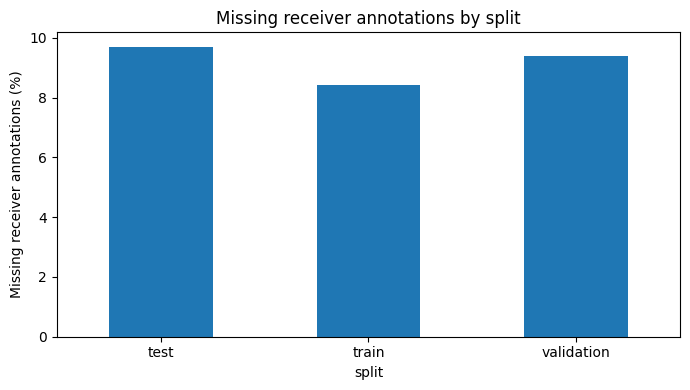

In [20]:
receiver_summary["missing_percent"].plot.bar(figsize=(7, 4))
plt.ylabel("Missing receiver annotations (%)")
plt.title("Missing receiver annotations by split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Check repeated messages and duplicate records

In [22]:
# Repeated message text (excluding first occurrence)
df["message"].duplicated().sum()


np.int64(497)

In [23]:
# Most frequently repeated messages
display(df["message"].value_counts(dropna=False).head(10).to_frame("count"))


,count
message,
Yes,20
Ok,17
Sure,16
?,15
Sounds good,14
👍,12
Lol,11
Yeah,10
Done,9


In [24]:
# Check exact duplicate conversation records inside each split.
for split, records in splits.items():
    fingerprints = [json.dumps(r, sort_keys=True, ensure_ascii=False) for r in records]
    duplicate_count = pd.Series(fingerprints).duplicated().sum()
    print(f"{split}: {duplicate_count} exact duplicate conversation records")

train: 0 exact duplicate conversation records
validation: 0 exact duplicate conversation records
test: 0 exact duplicate conversation records


#### Check game overlap between splits

If the same game appears in multiple splits, model evaluation may suffer from game-level leakage.

In [25]:
game_ids = {
    split: {record.get("game_id") for record in records}
    for split, records in splits.items()
}

for split, ids in game_ids.items():
    print(f"{split}: {len(ids)} unique games")

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = game_ids[a] & game_ids[b]
    print(f"{a} vs {b}: {len(overlap)} shared game IDs")
    if overlap:
        print("Shared IDs:", sorted(map(str, overlap)))

train: 9 unique games
validation: 1 unique games
test: 2 unique games
train vs validation: 0 shared game IDs
train vs test: 0 shared game IDs
validation vs test: 0 shared game IDs


#### Check message indices

Inspect missing or non-integer indices and repeated absolute indices within each game. Repeated indices are **flags for review**, since the meaning of the index must be verified before treating them as errors.

In [27]:
for field in ["absolute_message_index", "relative_message_index"]:
    missing = df[field].isna().sum()
    non_integer = (~df[field].map(
        lambda x: isinstance(x, int) and not isinstance(x, bool)
    )).sum()
    negative = df[field].map(
        lambda x: isinstance(x, int) and not isinstance(x, bool) and x < 0
    ).sum()
    print(f"{field}: missing={missing}, non_integer={non_integer}, negative={negative}")

repeated_indices = df.duplicated(
    subset=["split", "game_id", "absolute_message_index"], keep=False
)
print("Rows sharing a game-level absolute index:", repeated_indices.sum())

absolute_message_index: missing=0, non_integer=0, negative=0
relative_message_index: missing=0, non_integer=0, negative=0
Rows sharing a game-level absolute index: 0
